# data quality assessment ? Comprehensive data quality assessment

This notebook executes the read-only assessment across the 20 validated Excel/CSV tables. The inventory evidence workbook supplies table extents, header positions, date fields and identifier candidates. Source hashes and inventory artifact hashes are checked before and after the run.

Counts/statistics use full tables. Examples are limited and labeled. Ambiguous dates and source values remain unchanged; numerical and categorical interpretations are diagnostic copies only. Business requiredness, key identity, domains, source precedence and financial rules remain unconfirmed. The generated issue register records severity, impact, affected counts and recommendations. No cleaning, joins or model training are performed.

Implementation and report paths are relative to the project folder. See `reports/data_quality/data_quality_report.md` after execution.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
PROJECT = Path.cwd().resolve()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / 'src' / 'data'))
from assess_data_quality import run
REPORTS = PROJECT / 'reports' / 'data_quality'
print('Project:', PROJECT)


Project: D:\Aroha_Files\NOP_Project


In [2]:
# Executes complete-table assessments and writes only derived quality evidence.
results = run(PROJECT)
print('Assessment and report export validation completed.')


Assessed Customer Master Report 1.xlsx / Sheet1: 40 rows, 35 columns


Assessed Customer Master Report 2.xlsx / Sheet1: 5,015 rows, 35 columns


Assessed Exchange Rate 1.xlsx / INR to JPY: 7 rows, 7 columns


Assessed Exchange Rate.xlsx / INR to JPY: 22 rows, 7 columns


Assessed GSTR1_Credit_Debit_Note 1.csv / (CSV table): 6 rows, 64 columns


Assessed GSTR1_Credit_Debit_Note 2.csv / (CSV table): 279 rows, 64 columns


... (12 outputs left out)

Assessed Sales_Order_Data_202609.xlsx / PTC_NOPI: 60 rows, 8 columns


Assessed Sales_Order_Data_202609.xlsx / PCT_NOPJ: 33 rows, 9 columns


Assessment completed; sources and inventory evidence unchanged.


Assessment and report export validation completed.


In [3]:
display(results['source_tables'])
display(results['issue_register'].groupby('severity').size().rename('source/column/rule findings').to_frame())
display(results['missing_values'].sort_values('blank_percent_nonempty_rows', ascending=False).head(20))
display(results['duplicate_analysis'])


,file,worksheet,header_row,rows_below_header,nonempty_rows,empty_rows,columns,empty_data_columns,blank_cells,data_cells,blank_cell_percent,status
0,Customer Master Report 1.xlsx,Sheet1,1,40,40,0,35,15,632,1400,45.1429,assessed
1,Customer Master Report 2.xlsx,Sheet1,1,5015,5012,3,35,15,78719,175525,44.8477,assessed
2,Exchange Rate 1.xlsx,INR to JPY,4,7,7,0,7,1,7,49,14.2857,assessed
3,Exchange Rate.xlsx,INR to JPY,4,22,22,0,7,0,10,154,6.4935,assessed
4,GSTR1_Credit_Debit_Note 1.csv,(CSV table),1,6,6,0,64,5,30,384,7.8125,assessed
5,GSTR1_Credit_Debit_Note 2.csv,(CSV table),1,279,276,3,64,5,1980,17856,11.0887,assessed
6,GSTR1_Invoice.csv,(CSV table),1,337,337,0,68,12,4822,22916,21.0421,assessed
7,Inventory Audit Report as on 200327.xlsx,Sheet1,1,108129,108124,5,13,0,261403,1405677,18.5962,assessed
8,Inventory Audit Report as on 200926 1.xlsx,Sheet1,1,162,162,0,13,0,792,2106,37.6068,assessed
9,Inventory Audit Report as on 200926.xlsx,Sheet1,1,162,162,0,13,0,792,2106,37.6068,assessed


,source/column/rule findings
severity,
High,102
Low,104
Moderate,218


,file,worksheet,column_number,column_name,data_rows,blank_count,blank_percent_all_rows,nonempty_rows,blanks_on_nonempty_rows,blank_percent_nonempty_rows,completely_empty_data_column,placeholder_tokens_not_replaced,placeholder_count,applicability_assessment,requiredness_confirmed,business_confirmation,raw_data_types
16,Customer Master Report 1.xlsx,Sheet1,17,STREET / PO BOX,40,40,100.0,40,40,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}
454,Sales Order Report 1.xlsx,Sheet1,12,BP Catalog No,1098,1098,100.0,1098,1098,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}
15,Customer Master Report 1.xlsx,Sheet1,16,ADDRESS 3,40,40,100.0,40,40,100.0,True,{},0,conditionally optional candidate,False,"May apply only to amendments, advances, export...",{}
10,Customer Master Report 1.xlsx,Sheet1,11,SHIPPING TYPE,40,40,100.0,40,40,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}
7,Customer Master Report 1.xlsx,Sheet1,8,Fax Number,40,40,100.0,40,40,100.0,True,{},0,conditionally optional candidate,False,"May apply only to amendments, advances, export...",{}
482,Sales Order Report 2.xlsx,Sheet1,14,Item Details,100286,100286,100.0,100280,100280,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}
30,Customer Master Report 1.xlsx,Sheet1,31,SWIFT CODE / IFS CODE,40,40,100.0,40,40,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}
29,Customer Master Report 1.xlsx,Sheet1,30,BRANCH,40,40,100.0,40,40,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}
28,Customer Master Report 1.xlsx,Sheet1,29,BANK ACCOUNT NAME,40,40,100.0,40,40,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}
480,Sales Order Report 2.xlsx,Sheet1,12,BP Catalog No,100286,100286,100.0,100280,100280,100.0,True,{},0,requiredness unconfirmed,False,A required-field specification is not availabl...,{}


,file,worksheet,comparison,compared_columns,nonempty_rows,duplicate_groups,duplicate_excess_rows,rows_in_duplicate_groups,grain_confirmed
0,Customer Master Report 1.xlsx,Sheet1,all_raw_fields,"[""#"", ""CUSTOMER CODE"", ""CUSTOMER NAME"", ""CUSTO...",40,0,0,0,False
1,Customer Master Report 1.xlsx,Sheet1,all_fields_excluding_row_ordinal,"[""CUSTOMER CODE"", ""CUSTOMER NAME"", ""CUSTOMER G...",40,0,0,0,False
2,Customer Master Report 2.xlsx,Sheet1,all_raw_fields,"[""#"", ""CUSTOMER CODE"", ""CUSTOMER NAME "", ""CUS...",5012,0,0,0,False
3,Customer Master Report 2.xlsx,Sheet1,all_fields_excluding_row_ordinal,"[""CUSTOMER CODE"", ""CUSTOMER NAME "", ""CUSTOMER...",5012,15,15,30,False
4,Exchange Rate 1.xlsx,INR to JPY,all_raw_fields,"[""Rate Month "", ""Start Date"", ""End Date"", ""Fr...",7,0,0,0,False
5,Exchange Rate 1.xlsx,INR to JPY,all_fields_excluding_row_ordinal,"[""Rate Month "", ""Start Date"", ""End Date"", ""Fr...",7,0,0,0,False
6,Exchange Rate.xlsx,INR to JPY,all_raw_fields,"[""Rate Month"", ""Start Date"", ""End Date"", ""From...",22,0,0,0,False
7,Exchange Rate.xlsx,INR to JPY,all_fields_excluding_row_ordinal,"[""Rate Month"", ""Start Date"", ""End Date"", ""From...",22,0,0,0,False
8,GSTR1_Credit_Debit_Note 1.csv,(CSV table),all_raw_fields,"[""CreditDebitNote_Date"", ""CreditDebitNote_Numb...",6,0,0,0,False
9,GSTR1_Credit_Debit_Note 1.csv,(CSV table),all_fields_excluding_row_ordinal,"[""CreditDebitNote_Date"", ""CreditDebitNote_Numb...",6,0,0,0,False


In [4]:
display(results['date_quality'])
display(results['identifier_quality'].head(20))
display(results['financial_consistency'])
display(results['dataset_specific'])
display(results['categorical_consistency'].sort_values('outer_space_values', ascending=False).head(20))


,file,worksheet,column_number,column,raw_types,representative_original_values,nonblank_values,status_counts,ambiguous_values,invalid_calendar_values,possible_serial_values,unresolved_full_dates,month_period_values,unambiguous_min,unambiguous_max,unambiguous_distinct_dates,month_periods_observed,unobserved_months_within_partial_coverage,future_unambiguous_values,coverage_caveat
0,Exchange Rate 1.xlsx,INR to JPY,1,Rate Month,"{""text"": 7}","[{""type"": ""text"", ""value"": ""September 2026"", ""...",7,"{""month period, represented by first day"": 7}",0,0,0,0,7,,,0,"[""2026-09"", ""2026-10"", ""2026-11"", ""2026-12"", ""...",[],0,Excludes ambiguous/serial/invalid values. Two-...
1,Exchange Rate 1.xlsx,INR to JPY,2,Start Date,"{""datetime"": 2, ""text"": 3, ""number"": 2}","[{""type"": ""datetime"", ""value"": ""2026-08-21T00:...",7,"{""native Excel datetime"": 2, ""unambiguous DMY ...",0,0,2,2,0,2026-08-21,2027-01-21,5,[],"[""2026-10""]",3,Excludes ambiguous/serial/invalid values. Two-...
2,Exchange Rate 1.xlsx,INR to JPY,3,End Date,"{""text"": 4, ""datetime"": 2, ""number"": 1}","[{""type"": ""text"", ""value"": ""20-09-2026"", ""coun...",7,"{""unambiguous DMY by calendar"": 4, ""native Exc...",0,0,1,1,0,2026-09-20,2027-03-20,6,[],"[""2026-12""]",4,Excludes ambiguous/serial/invalid values. Two-...
3,Exchange Rate.xlsx,INR to JPY,1,Rate Month,"{""text"": 22}","[{""type"": ""text"", ""value"": ""Jan-25"", ""count"": ...",22,"{""month period, represented by first day"": 22}",0,0,0,0,22,,,0,"[""2025-01"", ""2025-02"", ""2025-03"", ""2025-04"", ""...",[],0,Excludes ambiguous/serial/invalid values. Two-...
4,Exchange Rate.xlsx,INR to JPY,2,Start Date,"{""datetime"": 22}","[{""type"": ""datetime"", ""value"": ""2024-12-21T00:...",22,"{""native Excel datetime"": 22}",0,0,0,0,0,2024-12-21,2026-09-21,22,[],[],0,Excludes ambiguous/serial/invalid values. Two-...
5,Exchange Rate.xlsx,INR to JPY,3,End Date,"{""datetime"": 22}","[{""type"": ""datetime"", ""value"": ""2025-01-20T00:...",22,"{""native Excel datetime"": 22}",0,0,0,0,0,2025-01-20,2026-10-20,22,[],[],0,Excludes ambiguous/serial/invalid values. Two-...
6,GSTR1_Credit_Debit_Note 1.csv,(CSV table),1,CreditDebitNote_Date,"{""text"": 6}","[{""type"": ""text"", ""value"": ""29-01-2026"", ""coun...",6,"{""unambiguous DMY by calendar"": 3, ""ambiguous ...",3,0,0,0,0,2026-01-29,2026-06-24,3,[],"[""2026-02"", ""2026-03"", ""2026-05""]",0,Excludes ambiguous/serial/invalid values. Two-...
7,GSTR1_Credit_Debit_Note 1.csv,(CSV table),4,Invoice_Date,"{""text"": 6}","[{""type"": ""text"", ""value"": ""05-01-2026"", ""coun...",6,"{""ambiguous day/month"": 3, ""unambiguous DMY by...",3,0,0,0,0,2026-01-18,2026-03-30,2,[],"[""2026-02""]",0,Excludes ambiguous/serial/invalid values. Two-...
8,GSTR1_Credit_Debit_Note 1.csv,(CSV table),28,Original_CreditDebitNote_Date,{},[],0,{},0,0,0,0,0,,,0,[],[],0,Excludes ambiguous/serial/invalid values. Two-...
9,GSTR1_Credit_Debit_Note 1.csv,(CSV table),47,Revision_Month,"{""text"": 6}","[{""type"": ""text"", ""value"": ""1"", ""count"": 3}, {...",6,"{""month number without year"": 6}",0,0,0,6,0,,,0,[],[],0,Excludes ambiguous/serial/invalid values. Two-...


,file,worksheet,column_number,column_name,initially_flagged,semantic_role,data_rows,null_or_blank_rows,nulls_on_nonempty_rows,entirely_empty_data_rows,...,empirical_primary_key_candidate,primary_key_confirmed,nonblank_uniqueness_percent,unique_value_percent_of_all_rows,null_percent,null_percent_nonempty_rows,granularity_note,candidate_matching_comparisons,matching_coverage_status,referential_constraint_confirmed
0,Customer Master Report 1.xlsx,Sheet1,1,#,True,row ordinal; not a business primary key,40,0,0,0,...,False,False,100.0000,100.0000,0.0000,0.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
1,Customer Master Report 1.xlsx,Sheet1,2,CUSTOMER CODE,True,entity/document reference; candidate only,40,0,0,0,...,True,False,100.0000,100.0000,0.0000,0.0000,Entity/document reference is not necessarily a...,5,See unconfirmed candidate matching comparisons,False
2,Customer Master Report 1.xlsx,Sheet1,3,CUSTOMER NAME,True,measure/descriptive attribute; sampled uniquen...,40,0,0,0,...,False,False,100.0000,100.0000,0.0000,0.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
3,Customer Master Report 1.xlsx,Sheet1,7,MOBILE PHONE,True,contact/location/bank attribute; uniqueness do...,40,0,0,0,...,False,False,100.0000,100.0000,0.0000,0.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
4,Customer Master Report 1.xlsx,Sheet1,8,Fax Number,True,contact/location/bank attribute; uniqueness do...,40,40,40,0,...,False,False,NaN,0.0000,100.0000,100.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
5,Customer Master Report 1.xlsx,Sheet1,15,ADDRESS 2,True,measure/descriptive attribute; sampled uniquen...,40,0,0,0,...,False,False,100.0000,100.0000,0.0000,0.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
6,Customer Master Report 1.xlsx,Sheet1,20,ZIP CODE,True,contact/location/bank attribute; uniqueness do...,40,0,0,0,...,False,False,100.0000,100.0000,0.0000,0.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
7,Customer Master Report 1.xlsx,Sheet1,23,STREET NO.,True,contact/location/bank attribute; uniqueness do...,40,40,40,0,...,False,False,NaN,0.0000,100.0000,100.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
8,Customer Master Report 1.xlsx,Sheet1,24,BUILDING/FLOOR/ROOM,True,measure/descriptive attribute; sampled uniquen...,40,0,0,0,...,False,False,100.0000,100.0000,0.0000,0.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False
9,Customer Master Report 1.xlsx,Sheet1,25,GSTIN,True,party/tax identifier; business semantics need ...,40,8,8,0,...,False,False,100.0000,80.0000,20.0000,20.0000,Entity/document reference is not necessarily a...,0,No semantically supported comparison defined; ...,False


,file,worksheet,check,input_columns,target_column,active_rows,evaluable_rows,unevaluable_rows,outside_tolerance_rows,absolute_tolerance,relative_tolerance,max_abs_difference_evaluable,source_row_examples,assumption,business_rule_confirmed
0,GSTR1_Credit_Debit_Note 1.csv,(CSV table),quantity × unit price versus taxable value,"[""Item_Quantity"", ""Item_Unit_Price""]",Item_Taxable_Value,6.0,6,0.0,0,1.0,0.005,0.000000e+00,[],Line-level same-unit values assumed; document ...,False
1,GSTR1_Credit_Debit_Note 1.csv,(CSV table),IGST taxable value × rate/100 versus amount,"[""Item_Taxable_Value"", ""IGST_Rate""]",IGST_Amount,6.0,6,0.0,0,1.0,0.005,0.000000e+00,[],Rate interpreted in percentage points on the r...,False
2,GSTR1_Credit_Debit_Note 1.csv,(CSV table),CGST taxable value × rate/100 versus amount,"[""Item_Taxable_Value"", ""CGST_Rate""]",CGST_Amount,6.0,6,0.0,0,1.0,0.005,0.000000e+00,[],Rate interpreted in percentage points on the r...,False
3,GSTR1_Credit_Debit_Note 1.csv,(CSV table),SGST taxable value × rate/100 versus amount,"[""Item_Taxable_Value"", ""SGST_Rate""]",SGST_Amount,6.0,6,0.0,0,1.0,0.005,0.000000e+00,[],Rate interpreted in percentage points on the r...,False
4,GSTR1_Credit_Debit_Note 1.csv,(CSV table),CESS taxable value × rate/100 versus amount,"[""Item_Taxable_Value"", ""CESS_Rate""]",CESS_Amount,6.0,6,0.0,0,1.0,0.005,0.000000e+00,[],Rate interpreted in percentage points on the r...,False
5,GSTR1_Credit_Debit_Note 1.csv,(CSV table),taxable value + GST/CESS components + non-GST ...,"[""Item_Taxable_Value"", ""IGST_Amount"", ""CGST_Am...",Line_Total_Include_GST,6.0,6,0.0,0,1.0,0.005,7.275958e-12,[],All reported line-level components must be pre...,False
6,GSTR1_Credit_Debit_Note 1.csv,(CSV table),Positive IGST together with positive CGST/SGST,NaN,NaN,NaN,6,NaN,0,NaN,NaN,NaN,[],Review mixed components with business team; no...,False
7,GSTR1_Credit_Debit_Note 2.csv,(CSV table),quantity × unit price versus taxable value,"[""Item_Quantity"", ""Item_Unit_Price""]",Item_Taxable_Value,276.0,276,0.0,118,1.0,0.005,2.194500e+06,"[5, 6, 8, 9, 10, 14, 15, 20, 21, 23]",Line-level same-unit values assumed; document ...,False
8,GSTR1_Credit_Debit_Note 2.csv,(CSV table),IGST taxable value × rate/100 versus amount,"["" Item_Taxable_Value"", ""IGST_Rate""]",IGST_Amount,276.0,276,0.0,0,1.0,0.005,5.000000e-03,[],Rate interpreted in percentage points on the r...,False
9,GSTR1_Credit_Debit_Note 2.csv,(CSV table),CGST taxable value × rate/100 versus amount,"["" Item_Taxable_Value"", ""CGST_Rate""]",CGST_Amount,276.0,276,0.0,0,1.0,0.005,5.000000e-03,[],Rate interpreted in percentage points on the r...,False


,file,worksheet,column,finding,affected_records,recommended_resolution,raw_values_and_counts,proposed_interpretation
0,Exchange Rate 1.xlsx,INR to JPY,preamble,Explicit synthetic-data marker in source title,7,Confirm the intended use and whether synthetic...,NaN,NaN
1,Exchange Rate.xlsx,INR to JPY,preamble,Explicit synthetic-data marker in source title,22,Confirm the intended use and whether synthetic...,NaN,NaN
2,GSTR1_Credit_Debit_Note 1.csv,(CSV table),document totals,Document totals may repeat on line-level rows;...,6,"Confirm document series, fiscal scope and line...",NaN,NaN
3,GSTR1_Credit_Debit_Note 2.csv,(CSV table),document totals,Document totals may repeat on line-level rows;...,276,"Confirm document series, fiscal scope and line...",NaN,NaN
4,GSTR1_Invoice.csv,(CSV table),document totals,Document totals may repeat on line-level rows;...,337,"Confirm document series, fiscal scope and line...",NaN,NaN
5,Sales Invoice Details 1.xlsx,Sheet1,document totals,Document totals may repeat on line-level rows;...,100183,"Confirm document series, fiscal scope and line...",NaN,NaN
6,Sales Invoice Details.xlsx,Sheet1,document totals,Document totals may repeat on line-level rows;...,337,"Confirm document series, fiscal scope and line...",NaN,NaN
7,Sales_Order_Data_202609.xlsx,Customer list,preamble,Explicit synthetic-data marker in source title,43,Confirm the intended use and whether synthetic...,NaN,NaN
8,Sales_Order_Data_202609.xlsx,PCT_NOPJ,<blank column 1>,Header is blank; data exists,33,Ask source owner for the field definition; ret...,"{""NOPJ"": 33}",Agency/source marker is plausible from neighbo...


,file,worksheet,column,category_candidate,text_values,raw_types,outer_space_values,repeated_internal_space_values,diagnostic_representation_collision_groups,case_variant_groups,domain_status
276,Sales Invoice Details 1.xlsx,Sheet1,Customer Type,True,58762,"{""text"": 58762}",7376,0,2,2,Allowed business values unconfirmed; observed ...
354,Sales Order Report 2.xlsx,Sheet1,Status,True,100280,"{""text"": 100280}",3245,0,4,4,Allowed business values unconfirmed; observed ...
357,Sales Order Report 2.xlsx,Sheet1,Item No,False,99259,"{""text"": 99259}",3082,0,2085,1316,Allowed business values unconfirmed; observed ...
349,Sales Order Report 2.xlsx,Sheet1,Customer Code,False,100280,"{""text"": 100280}",3061,0,1577,1053,Allowed business values unconfirmed; observed ...
284,Sales Invoice Details 1.xlsx,Sheet1,Part Code SAP Code,False,99242,"{""text"": 99242}",3012,0,2044,1292,Allowed business values unconfirmed; observed ...
229,Inventory Audit Report as on 200327.xlsx,Sheet1,Whse,False,98104,"{""text"": 98104}",2868,0,2,0,Allowed business values unconfirmed; observed ...
277,Sales Invoice Details 1.xlsx,Sheet1,Invoice Num,False,100183,"{""text"": 100183}",2267,0,2637,1336,Allowed business values unconfirmed; observed ...
231,Inventory Audit Report as on 200327.xlsx,Sheet1,Trans. Value,False,7794,"{""number"": 100330, ""text"": 7794}",1915,0,0,0,Allowed business values unconfirmed; observed ...
301,Sales Invoice Details 1.xlsx,Sheet1,Customer Billing GSTIN,False,82869,"{""text"": 82869}",1865,0,1045,668,Allowed business values unconfirmed; observed ...
281,Sales Invoice Details 1.xlsx,Sheet1,State Place of Supply,False,83220,"{""text"": 83220}",1834,0,7,7,Allowed business values unconfirmed; observed ...


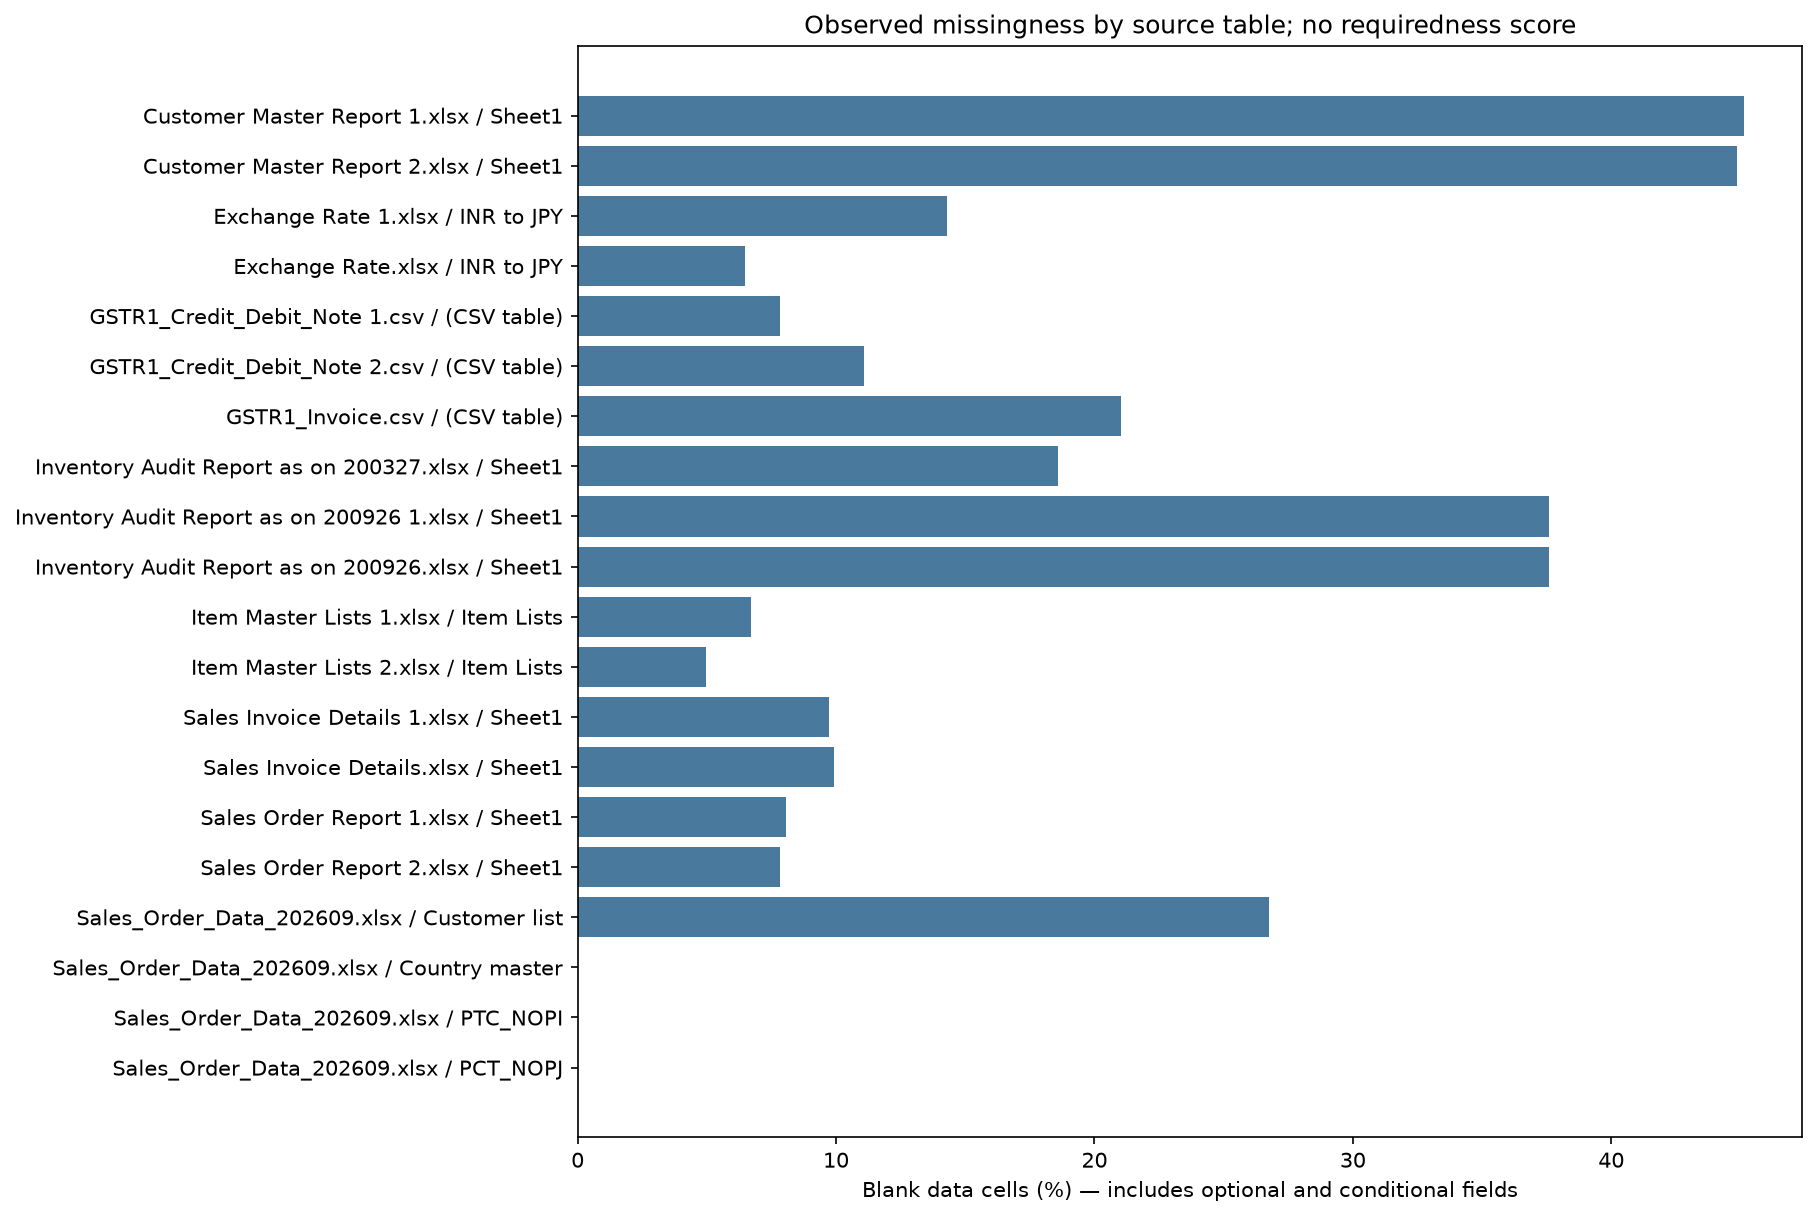

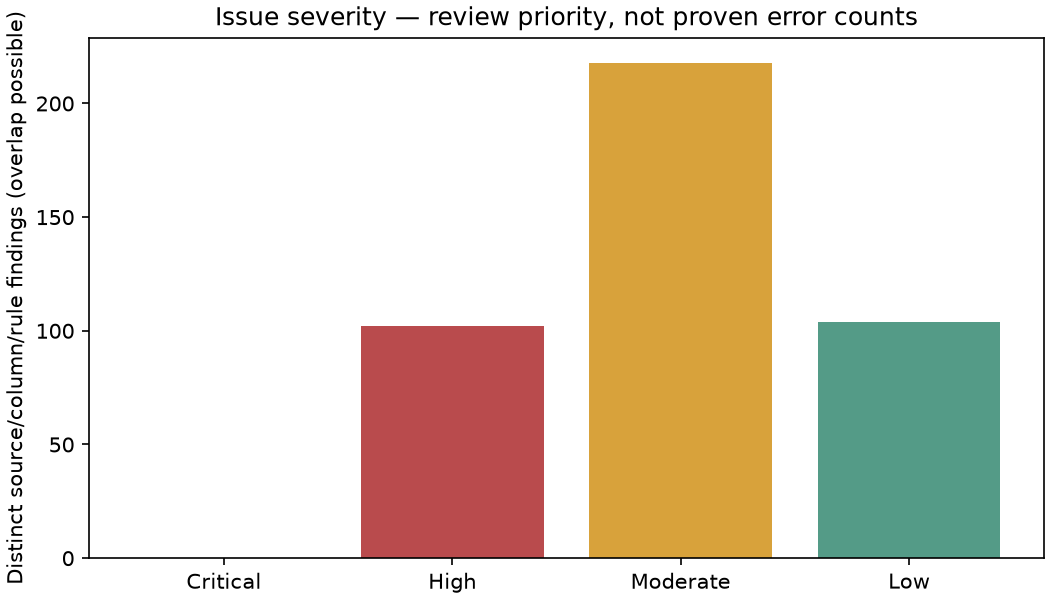

{
  "configuration": {
    "as_of": "2026-10-30",
    "excessive_missing_percent": 50.0,
    "outlier_iqr_multiplier": 3.0,
    "money_absolute_tolerance": 1.0,
    "money_relative_tolerance": 0.005,
    "normalization": "Diagnostic copies only; raw values preserved. Case/spacing equivalence requires confirmation."
  },
  "files": 17,
  "excel_workbooks": 14,
  "excel_worksheets": 17,
  "csv_tables": 3,
  "tables": 20,
  "column_profiles": 521,
  "identifier_candidates": 135,
  "date_fields": 37,
  "inventory_artifacts_preserved": 23,
  "all_source_hashes_unchanged": true,
  "date_counts": {
    "ambiguous": 203455,
    "impossible": 28,
    "unconfirmed_serial": 14949
  },
  "issue_counts_by_severity": {
    "Moderate": 218,
    "Low": 104,
    "High": 102
  },
  "read_failures": 0,
  "business_primary_keys_confirmed": 0
}
Final report: D:\Aroha_Files\NOP_Project\reports\data_quality\data_quality_report.md


In [5]:
display(Image(filename=str(REPORTS / 'missingness_by_table.png')))
display(Image(filename=str(REPORTS / 'issue_severity.png')))
validation = json.loads((REPORTS / 'assessment_validation.json').read_text(encoding='utf-8'))
assert validation['tables'] == 20 and validation['identifier_candidates'] == 135
assert validation['date_counts'] == {'ambiguous': 203455, 'impossible': 28, 'unconfirmed_serial': 14949}
assert validation['all_source_hashes_unchanged'] and validation['read_failures'] == 0
assert all(row['csv_content_verified'] and row['excel_content_verified'] is not False for row in validation['export_checks'])
print(json.dumps({key:value for key,value in validation.items() if key != 'export_checks'}, indent=2))
print('Final report:', REPORTS / 'data_quality_report.md')


## Review boundary

This notebook records the data quality assessment. Read the executive summary and full issue register before approving data preparation. The counts are review evidence, not automatic decisions to drop records, impute values, normalize categories, confirm keys or establish relationships.